# Retail Promotion Effectiveness & Discount Sensitivity Analysis
## 02 — Promotion EDA

Describes observed sales, quantities, products, and promotional conditions. Promotions were not randomly assigned, so results are associations rather than incremental lift.

## Imports

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)

## Config (file paths, plotting style, and reproducibility)

In [2]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Run from the repository or notebooks directory.')
PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_utils import add_bar_labels, add_promotion_fields, bootstrap_ci, summarize_frame
RANDOM_STATE = 42
ALPHA = 0.05
POWER = 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

## Data Cleaning and Preprocessing

The audited output from notebook 01 is checked again. Required-field missing rows and exact duplicates are removed only after counts are printed; outliers are retained.

In [3]:
df = pd.read_csv(PROCESSED_DIR / 'transaction_product_analysis.csv.gz', low_memory=False)

In [4]:
summarize_frame('processed transactions', df, 'SALES_VALUE')

processed transactions row count: 2,595,732
processed transactions column count: 23
processed transactions null counts:
household_key               0
BASKET_ID                   0
DAY                         0
PRODUCT_ID                  0
QUANTITY                    0
SALES_VALUE                 0
STORE_ID                    0
RETAIL_DISC                 0
TRANS_TIME                  0
WEEK_NO                     0
COUPON_DISC                 0
COUPON_MATCH_DISC           0
MANUFACTURER                0
DEPARTMENT                  0
BRAND                       0
COMMODITY_DESC              0
SUB_COMMODITY_DESC          0
CURR_SIZE_OF_PRODUCT        0
discount_amount             0
gross_value_proxy           0
discount_rate           10138
promotion_type              0
is_discounted               0


processed transactions exact duplicate count: 0
processed transactions DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 23 columns):
 #   Column                Dtype  
---  ------                -----  
 0   household_key         int64  
 1   BASKET_ID             int64  
 2   DAY                   int64  
 3   PRODUCT_ID            int64  
 4   QUANTITY              int64  
 5   SALES_VALUE           float64
 6   STORE_ID              int64  
 7   RETAIL_DISC           float64
 8   TRANS_TIME            int64  
 9   WEEK_NO               int64  
 10  COUPON_DISC           float64
 11  COUPON_MATCH_DISC     float64
 12  MANUFACTURER          int64  
 13  DEPARTMENT            str    
 14  BRAND                 str    
 15  COMMODITY_DESC        str    
 16  SUB_COMMODITY_DESC    str    
 17  CURR_SIZE_OF_PRODUCT  str    
 18  discount_amount       float64
 19  gross_value_proxy     float64
 20  discount_rate         float64
 21  p

In [5]:
needed = ['household_key','BASKET_ID','PRODUCT_ID','SALES_VALUE','QUANTITY','promotion_type','is_discounted']
print('Rows missing required fields:', f'{df[needed].isna().any(axis=1).sum():,}')
analysis_df = df.dropna(subset=needed).drop_duplicates().copy()
print('Rows after dropna and exact deduplication:', f'{len(analysis_df):,}')
print('No single-row ID exists; basket-product repetitions may be valid.')

Rows missing required fields: 0


Rows after dropna and exact deduplication: 2,595,732
No single-row ID exists; basket-product repetitions may be valid.


## Column Description

One line per analytical column with observed type.

In [6]:
display(pd.DataFrame({'column':analysis_df.columns,'type':analysis_df.dtypes.astype(str).values}))

,column,type
0,household_key,int64
1,BASKET_ID,int64
2,DAY,int64
3,PRODUCT_ID,int64
4,QUANTITY,int64
5,SALES_VALUE,float64
6,STORE_ID,int64
7,RETAIL_DISC,float64
8,TRANS_TIME,int64
9,WEEK_NO,int64


## EDA

Promotion denominators are transaction lines unless explicitly labeled as baskets or households. Percentage values are shown to two decimals.

In [7]:
promotion_summary = analysis_df.groupby('promotion_type',observed=True).agg(transaction_lines=('PRODUCT_ID','size'),households=('household_key','nunique'),sales_value=('SALES_VALUE','sum'),quantity=('QUANTITY','sum'),median_line_sales=('SALES_VALUE','median'),median_line_quantity=('QUANTITY','median'),mean_discount_rate=('discount_rate','mean')).reset_index()
promotion_summary['line_share_pct'] = 100*promotion_summary.transaction_lines/len(analysis_df)
promotion_summary['sales_share_pct'] = 100*promotion_summary.sales_value/promotion_summary.sales_value.sum()
display(promotion_summary.sort_values('transaction_lines',ascending=False))
promotion_summary.to_csv(PROCESSED_DIR/'promotion_summary.csv',index=False)

,promotion_type,transaction_lines,households,sales_value,quantity,median_line_sales,median_line_quantity,mean_discount_rate,line_share_pct,sales_share_pct
3,Retail only,1282977,2500,3981538.12,258929977,2.00,1.0,0.265844,49.426405,49.414289
1,No recorded discount,1276333,2500,3948520.27,1711790,2.29,1.0,0.000000,49.170446,49.004510
2,Retail + coupon,20049,1546,74554.05,29423,2.50,1.0,0.456123,0.772383,0.925279
0,Coupon only,16373,1568,52850.64,14432,2.19,1.0,0.493116,0.630766,0.655922


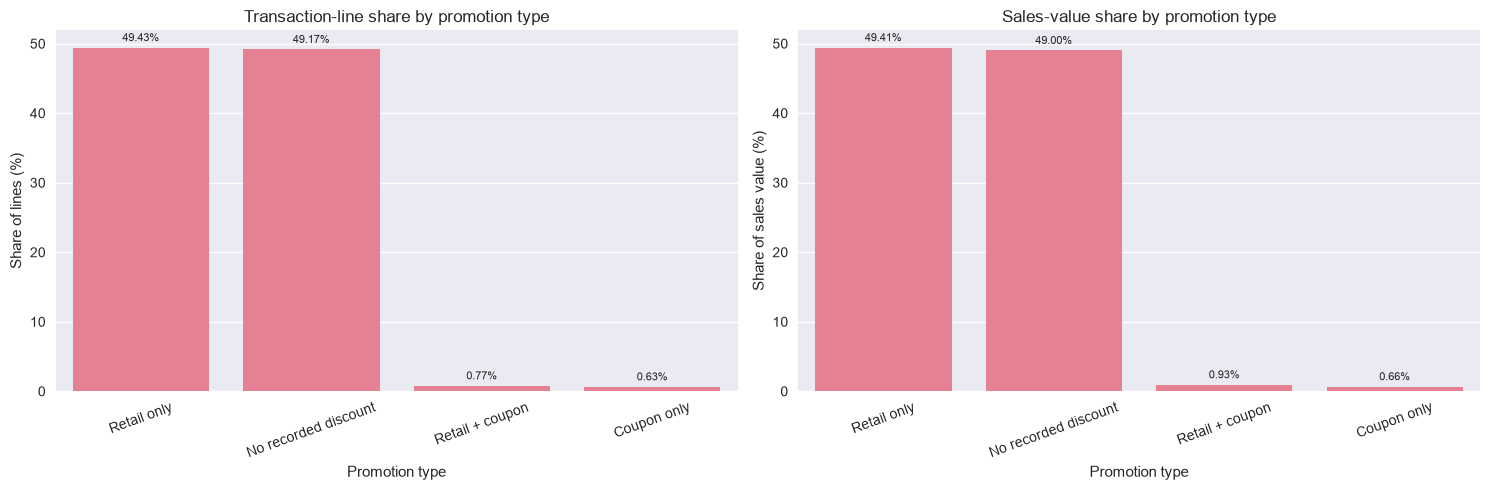

In [8]:
fig,axes=plt.subplots(1,2,figsize=(15,5)); order=promotion_summary.sort_values('line_share_pct',ascending=False)
sns.barplot(data=order,x='promotion_type',y='line_share_pct',ax=axes[0]); axes[0].set(title='Transaction-line share by promotion type',xlabel='Promotion type',ylabel='Share of lines (%)'); axes[0].tick_params(axis='x',rotation=20); add_bar_labels(axes[0],True)
sns.barplot(data=order,x='promotion_type',y='sales_share_pct',ax=axes[1]); axes[1].set(title='Sales-value share by promotion type',xlabel='Promotion type',ylabel='Share of sales value (%)'); axes[1].tick_params(axis='x',rotation=20); add_bar_labels(axes[1],True)
plt.tight_layout(); plt.show()

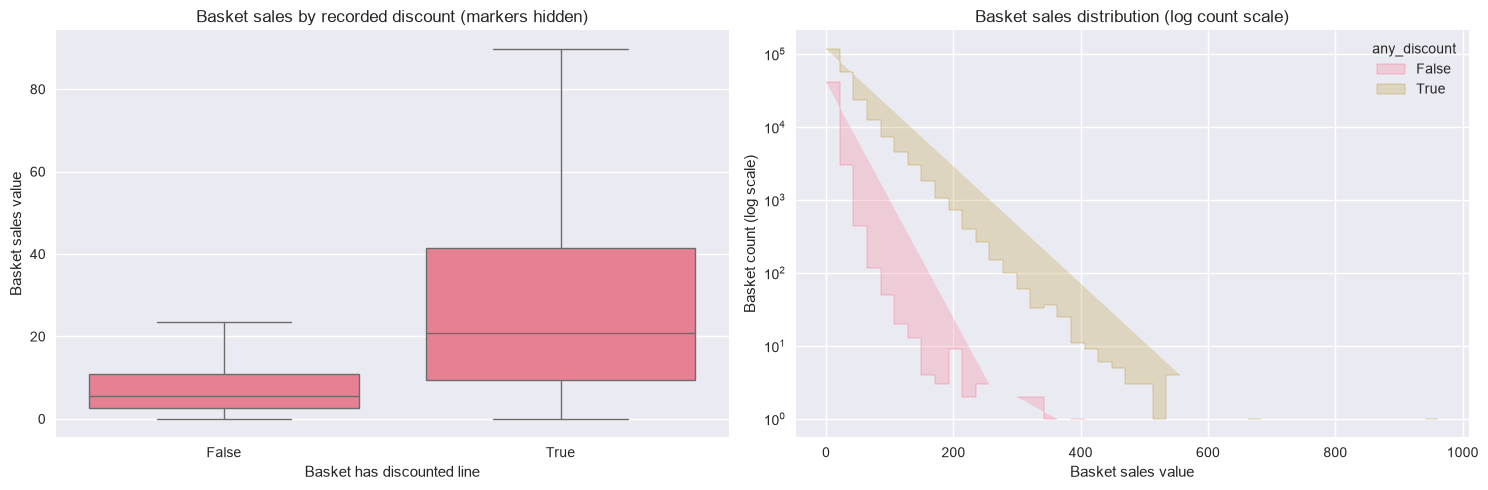

In [9]:
basket_summary=analysis_df.groupby(['household_key','BASKET_ID'],as_index=False).agg(basket_sales=('SALES_VALUE','sum'),basket_quantity=('QUANTITY','sum'),any_discount=('is_discounted','max'),distinct_products=('PRODUCT_ID','nunique'))
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.boxplot(data=basket_summary,x='any_discount',y='basket_sales',showfliers=False,ax=axes[0]); axes[0].set(title='Basket sales by recorded discount (markers hidden)',xlabel='Basket has discounted line',ylabel='Basket sales value')
sns.histplot(data=basket_summary,x='basket_sales',hue='any_discount',bins=45,element='step',log_scale=(False,True),ax=axes[1]); axes[1].set(title='Basket sales distribution (log count scale)',xlabel='Basket sales value',ylabel='Basket count (log scale)')
plt.tight_layout(); plt.show()

## Problem Statement

Compare observed transaction outcomes while respecting repeated observations. Formal inference uses paired household summaries instead of treating millions of lines as independent.

## Question 1 — How do sales and quantities vary by promotion condition?

This is descriptive. The displayed table uses transaction-line denominators and does not estimate incremental impact.

In [10]:
display(promotion_summary[['promotion_type','transaction_lines','line_share_pct','median_line_sales','median_line_quantity','mean_discount_rate']].sort_values('line_share_pct',ascending=False))

,promotion_type,transaction_lines,line_share_pct,median_line_sales,median_line_quantity,mean_discount_rate
3,Retail only,1282977,49.426405,2.00,1.0,0.265844
1,No recorded discount,1276333,49.170446,2.29,1.0,0.000000
2,Retail + coupon,20049,0.772383,2.50,1.0,0.456123
0,Coupon only,16373,0.630766,2.19,1.0,0.493116


## Question 2 — Within households, do mean basket sales differ between baskets with and without recorded discounts?

**Objective:** compare each household's mean discounted-basket sales with its mean non-discounted-basket sales. $H_0$: median paired difference is zero. $H_1$: it is nonzero. $\alpha=0.05$ and planning power $=0.80$.

The paired-normal planning approximation is $n=((z_{1-\alpha/2}+z_{1-\beta})\sigma_d/\Delta)^2$. $\Delta$ is 5% of overall median basket value, an operational threshold rather than a claimed effect. Skewed paired differences are tested with Wilcoxon. Association is not causation.

In [11]:
def sample_size_paired(std_difference, minimum_detectable_difference, alpha=.05, power=.80):
    return int(np.ceil(((stats.norm.ppf(1-alpha/2)+stats.norm.ppf(power))*std_difference/minimum_detectable_difference)**2))
pairs=basket_summary.groupby(['household_key','any_discount']).basket_sales.mean().unstack().dropna().rename(columns={False:'no_discount',True:'discount'})
pairs['difference']=pairs.discount-pairs.no_discount
mde=.05*basket_summary.basket_sales.median(); required_n=sample_size_paired(pairs.difference.std(),mde); available_n=len(pairs); analysis_n=min(required_n,available_n)
paired_sample=pairs.sample(n=analysis_n,random_state=RANDOM_STATE)
print(f'MDE: {mde:.4f}; required: {required_n:,}; available: {available_n:,}; analyzed: {analysis_n:,}')
print('Power target not met.' if available_n<required_n else 'Planning target met.')

MDE: 0.8535; required: 3,586; available: 2,387; analyzed: 2,387
Power target not met.


In [12]:
subset=paired_sample.difference.sample(min(5000,len(paired_sample)),random_state=RANDOM_STATE)
shapiro_stat,shapiro_p=stats.shapiro(subset)
print(f'Difference skewness: {stats.skew(paired_sample.difference):.4f}')
print(f'Shapiro-Wilk: {shapiro_stat:.4f}; p={shapiro_p:.6g}')
print('Wilcoxon is used for paired, non-normal differences; an unpaired t-test would violate independence.')

Difference skewness: 1.7113
Shapiro-Wilk: 0.8844; p=5.43653e-39
Wilcoxon is used for paired, non-normal differences; an unpaired t-test would violate independence.


In [13]:
test_stat,p_value=stats.wilcoxon(paired_sample.difference,alternative='two-sided',zero_method='wilcox')
effect=paired_sample.difference.median(); ci_low,ci_high=bootstrap_ci(paired_sample.difference,np.median,random_state=RANDOM_STATE)
nonzero=paired_sample.loc[paired_sample.difference!=0,'difference']; ranks=stats.rankdata(abs(nonzero)); rank_biserial=(ranks[nonzero>0].sum()-ranks[nonzero<0].sum())/ranks.sum()
decision='Reject H0' if p_value<ALPHA else 'Fail to reject H0'
print(f'Wilcoxon statistic: {test_stat:.4f}; p-value: {p_value:.6g}')
print(f'Median paired difference: {effect:.4f}; 95% bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]')
print(f'Rank-biserial effect size: {rank_biserial:.4f}')
print(f'{decision}; this is an observed within-household association.')

Wilcoxon statistic: 9259.0000; p-value: 0
Median paired difference: 19.8959; 95% bootstrap CI: [19.3170, 20.5759]
Rank-biserial effect size: 0.9935
Reject H0; this is an observed within-household association.


In [14]:
pd.DataFrame([{'analysis':'paired household basket sales','n':analysis_n,'required_n':required_n,'effect_value':effect,'ci_low':ci_low,'ci_high':ci_high,'statistic':test_stat,'p_value':p_value,'rank_biserial':rank_biserial}]).to_csv(PROCESSED_DIR/'promotion_inference.csv',index=False)

## Summary

- Promotion mix and robust outcomes use explicit denominators.
- Basket distributions are skewed.
- The paired analysis reports planning adequacy, assumptions, effect size, interval, statistic, and decision.

## Insights

- Any gap is observational, not incremental lift.
- Sales value is not profit.
- Randomized household/store holdouts are needed for causal decisions.